# 03 — Item-Based Collaborative Filtering

**Ide dasar:** jika seorang user menyukai film A, ia kemungkinan juga menyukai film lain yang **pola
ratingnya mirip** dengan film A. Bedanya dengan user-based CF: yang dicari kemiripannya adalah **film**,
bukan user. Teknik ini dipakai Amazon karena jumlah item biasanya lebih stabil daripada jumlah user.

Langkah-langkah (sesuai slide M03):
1. Hitung kemiripan antar-film dengan **cosine** atau **adjusted cosine similarity**.
2. Untuk menebak rating user u pada film p, ambil **k film paling mirip** dengan p yang sudah dirating u.
3. Prediksi = rata-rata tertimbang rating user u pada film-film tersebut (bobot = similarity).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
RES = ROOT / "results"; RES.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import plot_style as ps
ps.setup()
pd.set_option("display.precision", 4)
from src.data import load_fold, load_ratings, load_items, to_matrix, unique_titles
from src.metrics import evaluate
from src.ibcf import ItemBasedCF, item_similarity

## Langkah 0 — Memastikan kode benar dengan contoh di slide

**Contoh film (slide M03).** Cosine biasa dihitung hanya dari user yang merating kedua film. Untuk Pulp
Fiction (P) dan Forrest Gump (F), user yang merating keduanya adalah Calvin, Robert, dan Bradley:

$$\cos(P, F) = \frac{5 \cdot 2 + 3 \cdot 3 + 1 \cdot 3}{\sqrt{5^2 + 3^2 + 1^2}\ \sqrt{2^2 + 3^2 + 3^2}} = \frac{22}{\sqrt{35}\sqrt{22}} = 0{,}792$$

In [2]:
nan = np.nan
film = np.array([[4, nan, 5],     # Amy
                 [5, 2, nan],     # Calvin
                 [3, 3, 1],       # Robert
                 [nan, 2, 2],     # David
                 [1, 3, nan]])    # Bradley
judul = ["Pulp Fiction", "Forrest Gump", "The GodFather"]
sim_film, _ = item_similarity(film, adjusted=False)
pd.DataFrame(sim_film + np.eye(3), index=judul, columns=judul).round(3)

,Pulp Fiction,Forrest Gump,The GodFather
Pulp Fiction,1.000,0.793,0.902
Forrest Gump,0.793,1.000,0.868
The GodFather,0.902,0.868,1.000


Hasil kode sama dengan slide untuk Pulp Fiction–Forrest Gump (22 / 27,749 = 0,7928, di slide ditulis 0,792)
dan Pulp Fiction–GodFather (0,902).
Untuk Forrest Gump–GodFather, slide menulis 0,8, sedangkan kode menghasilkan 0,868. Jika dihitung manual
dari user yang merating keduanya (Robert: 3 dan 1, David: 2 dan 2):

$$\cos(F, G) = \frac{3 \cdot 1 + 2 \cdot 2}{\sqrt{3^2 + 2^2}\ \sqrt{1^2 + 2^2}} = \frac{7}{\sqrt{13}\sqrt{5}} = 0{,}868$$

Jadi angka 0,8 di slide kemungkinan hasil pembulatan atau salah ketik, dan kode sudah benar.

**Contoh Alice (slide M03).** Kemiripan Item5 dan Item1 dengan cosine biasa = 0,99, sedangkan dengan
adjusted cosine = 0,80.

In [3]:
alice = np.array([[5, 3, 4, 4, nan],
                  [3, 1, 2, 3, 3],
                  [4, 3, 4, 3, 5],
                  [3, 3, 1, 5, 4],
                  [1, 5, 5, 2, 1]])
cos, _ = item_similarity(alice, adjusted=False)
adj, _ = item_similarity(alice, adjusted=True)
print(f"cosine biasa   sim(I5, I1) = {cos[4, 0]:.2f}")
print(f"adjusted cosine sim(I5, I1) = {adj[4, 0]:.2f}")

cosine biasa   sim(I5, I1) = 0.99
adjusted cosine sim(I5, I1) = 0.80


### Mengapa adjusted cosine?

Pada cosine biasa, semua rating bernilai positif (1–5), sehingga hampir semua pasangan film terlihat
"mirip" (nilainya mendekati 1). Cosine biasa juga tidak memperhitungkan kebiasaan user: rating 3 dari user
yang biasanya memberi 5 sebenarnya berarti "kurang suka".

Adjusted cosine mengurangi setiap rating dengan **rata-rata rating user tersebut** sebelum dihitung:

$$sim(a,b) = \frac{\sum_{u \in U} (r_{u,a} - \bar{r}_u)(r_{u,b} - \bar{r}_u)}
{\sqrt{\sum_{u \in U} (r_{u,a} - \bar{r}_u)^2}\ \sqrt{\sum_{u \in U} (r_{u,b} - \bar{r}_u)^2}}$$

- $U$ = user yang merating film a **dan** film b
- $\bar{r}_u$ = rata-rata seluruh rating user u
- Hasilnya bisa negatif (−1 sampai 1), seperti Pearson.

## Langkah 1 — Menyiapkan data fold 1

In [4]:
train, test = load_fold(1)
R = to_matrix(train)
titles = load_items()
print("Ukuran matriks R (user x film):", R.shape)

Ukuran matriks R (user x film): (943, 1682)


## Langkah 2 — Menghitung kemiripan antar-film

Matriks similarity berukuran 1.682 × 1.682. Agar terlihat bedanya, berikut 5 film paling mirip dengan
**Star Wars (1977)** menurut cosine biasa dan menurut adjusted cosine. Significance weighting (γ = 50)
dipakai di keduanya, dengan alasan yang sama seperti di user-based CF.

In [5]:
star_wars = 50 - 1   # id film 50, indeks 49
rows = []
for nama_varian, adjusted in [("Cosine biasa", False), ("Adjusted cosine", True)]:
    m = ItemBasedCF(adjusted=adjusted, sig_weight=50).fit(R)
    top = np.argsort(-m.sim[star_wars])[:5]
    for r, j in enumerate(top, 1):
        rows.append({"Varian": nama_varian, "Peringkat": r, "Film": titles[j + 1],
                     "sim": m.sim[star_wars, j], "User co-rated": int(m.n_common[star_wars, j])})
pd.DataFrame(rows).set_index(["Varian", "Peringkat"])

Film     sim  \
Varian          Peringkat                                                
Cosine biasa    1              Empire Strikes Back, The (1980)  0.9893   
                2                    Return of the Jedi (1983)  0.9853   
                3               Raiders of the Lost Ark (1981)  0.9819   
                4                        Close Shave, A (1995)  0.9800   
                5          20,000 Leagues Under the Sea (1954)  0.9792   
Adjusted cosine 1              Empire Strikes Back, The (1980)  0.8169   
                2                    Return of the Jedi (1983)  0.7310   
                3               Raiders of the Lost Ark (1981)  0.7203   
                4                        Close Shave, A (1995)  0.7181   
                5                   Usual Suspects, The (1995)  0.6273   

                           User co-rated  
Varian          Peringkat                 
Cosine biasa    1                    244  
                2                    353  
                3                    268  
                4                     62  
                5                     50  
Adjusted cosine 1                    244  
                2                    353  
                3                    268  
                4                     62  
                5                    161

## Langkah 3 — Membuat satu prediksi secara rinci

$$pred(u,p) = \frac{\sum_{i \in N} sim(i,p) \cdot r_{u,i}}{\sum_{i \in N} sim(i,p)}$$

- $N$ = k film paling mirip dengan film p (similarity positif) yang **sudah dirating** user u
- $r_{u,i}$ = rating user u untuk film i
- Artinya: "rating user untuk film p kira-kira sama dengan rating yang ia berikan pada film-film yang
  mirip dengan p, dengan film yang lebih mirip diberi bobot lebih besar".

In [6]:
model = ItemBasedCF(k=30, adjusted=True, sig_weight=50).fit(R)
contoh = test[test["user"] == 1].iloc[0]
u, p = contoh["user"] - 1, contoh["item"] - 1
cand, s = model.neighbors(u, p)
rinci = pd.DataFrame({"film mirip": [titles[j + 1] for j in cand], "sim": s, "rating user": R[u, cand]})
rinci["sim_x_rating"] = rinci["sim"] * rinci["rating user"]
rinci = rinci.sort_values("sim", ascending=False)
display(rinci.head(10))
pembilang, penyebut = rinci["sim_x_rating"].sum(), rinci["sim"].sum()
print(f"Prediksi user {u+1} untuk '{titles[p+1]}':")
print(f"  sum(sim x rating) = {pembilang:.4f}")
print(f"  sum(sim)          = {penyebut:.4f}")
print(f"  pred = {pembilang:.4f} / {penyebut:.4f} = {pembilang / penyebut:.4f}")
print(f"  rating asli       = {contoh['rating']}")

,film mirip,sim,rating user,sim_x_rating
0,Chasing Amy (1997),0.0842,5.0,0.4209
1,When Harry Met Sally... (1989),0.0753,5.0,0.3764
2,"Fugitive, The (1993)",0.0747,4.0,0.2989
3,Starship Troopers (1997),0.0728,2.0,0.1456
4,"Birdcage, The (1996)",0.0709,4.0,0.2836
5,Beavis and Butt-head Do America (1996),0.0621,3.0,0.1862
6,Mystery Science Theater 3000: The Movie (1996),0.0612,5.0,0.3060
7,"Empire Strikes Back, The (1980)",0.0579,5.0,0.2895
8,Return of the Jedi (1983),0.0572,5.0,0.2861
9,"Frighteners, The (1996)",0.0539,4.0,0.2156


Prediksi user 1 untuk 'Shanghai Triad (Yao a yao yao dao waipo qiao) (1995)':
  sum(sim x rating) = 5.5337
  sum(sim)          = 1.4615
  pred = 5.5337 / 1.4615 = 3.7864
  rating asli       = 5


## Langkah 4 — Prediksi seluruh data uji fold 1 dan evaluasi

Kolom `n_tetangga` menunjukkan berapa film mirip yang dipakai. Jika 0 (misalnya film tidak pernah muncul
di data latih), prediksi memakai cadangan, yaitu rata-rata rating user.

In [7]:
pred = model.predict_df(test)
display(pred.head(8))
print(f"Prediksi yang memakai cadangan (tanpa tetangga): {(pred['n_tetangga'] == 0).sum()} dari {len(pred)}")
pd.Series(evaluate(pred)).to_frame("IBCF fold 1")

,user,item,rating,timestamp,pred,n_tetangga
0,1,6,5,887431973,3.7864,30
1,1,10,3,875693118,4.1831,30
2,1,12,5,878542960,4.4833,30
3,1,14,5,874965706,4.3545,30
4,1,17,3,875073198,3.4896,30
5,1,20,4,887431883,4.1321,30
6,1,23,4,875072895,4.3421,30
7,1,24,3,875071713,4.1898,30


Prediksi yang memakai cadangan (tanpa tetangga): 37 dari 20000


,IBCF fold 1
MAE,0.7523
MSE,0.9301
RMSE,0.9644
NMSE,0.2325
NDCG@10,0.8308


## Analisis: cosine biasa vs adjusted cosine, dan pengaruh k

Slide M03 meminta perbandingan cosine dan adjusted cosine. Seperti di user-based CF, konfigurasi akhir
(**adjusted cosine, k = 30, γ = 50**) ditetapkan sebelum melihat hasil; nilai k = 30 mengikuti ukuran
tetangga yang disarankan Sarwar et al. (2001) untuk item-based CF. Tabel ini hanya analisis sensitivitas.

In [8]:
varian = [("Cosine biasa", False, None), ("Cosine biasa + sig. weighting", False, 50),
          ("Adjusted cosine", True, None), ("Adjusted cosine + sig. weighting", True, 50)]
rows = []
for label, adjusted, sw in varian:
    m = ItemBasedCF(adjusted=adjusted, sig_weight=sw).fit(R)
    for k in [10, 20, 30, 50, 100]:
        m.k = k
        rows.append({"Varian": label, "k": k, **evaluate(m.predict_df(test))})
sens = pd.DataFrame(rows)
sens.to_csv(RES / "ibcf_sensitivitas.csv", index=False)
sens[sens["k"] == 30].set_index("Varian").drop(columns="k").round(4)

,MAE,MSE,RMSE,NMSE,NDCG@10
Varian,,,,,
Cosine biasa,0.8283,1.1042,1.0508,0.2761,0.7510
Cosine biasa + sig. weighting,0.8556,1.2107,1.1003,0.3027,0.7674
Adjusted cosine,0.7851,0.9933,0.9966,0.2483,0.8210
Adjusted cosine + sig. weighting,0.7523,0.9301,0.9644,0.2325,0.8308


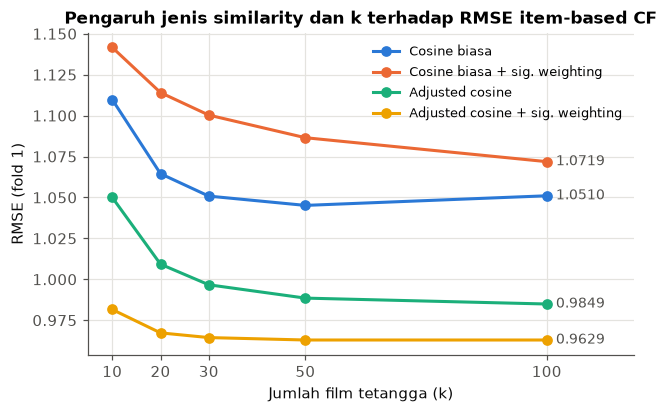

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for (label, g), color in zip(sens.groupby("Varian", sort=False), ps.SERIES):
    ax.plot(g["k"], g["RMSE"], marker="o", color=color, label=label)
    ax.annotate(f"{g['RMSE'].iloc[-1]:.4f}", (g["k"].iloc[-1], g["RMSE"].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=ps.INK_2)
ax.set_xlabel("Jumlah film tetangga (k)")
ax.set_ylabel("RMSE (fold 1)")
ax.set_title("Pengaruh jenis similarity dan k terhadap RMSE item-based CF")
ax.set_xticks([10, 20, 30, 50, 100])
ax.set_xlim(5, 118)
ax.legend(loc="upper right", fontsize=8.5)
fig.savefig(FIG / "ibcf_sensitivitas_k.png")
plt.show()

## Langkah 5 — Evaluasi di kelima fold

In [10]:
rows = []
for k in range(1, 6):
    tr, te = load_fold(k)
    m = ItemBasedCF(k=30, adjusted=True, sig_weight=50).fit(to_matrix(tr))
    p = m.predict_df(te)
    rows.append({"Fold": k, **evaluate(p), "Cadangan": float((p["n_tetangga"] == 0).sum())})
ibcf_5fold = pd.DataFrame(rows).set_index("Fold")
ibcf_5fold.loc["Rata-rata"] = ibcf_5fold.mean()
ibcf_5fold.loc["Simpangan baku"] = ibcf_5fold.iloc[:5].std()
ibcf_5fold.to_csv(RES / "ibcf_5fold.csv")
ibcf_5fold.round(4)

,MAE,MSE,RMSE,NMSE,NDCG@10,Cadangan
Fold,,,,,,
1,0.7523,0.9301,0.9644,0.2325,0.8308,37.0000
2,0.7354,0.8908,0.9438,0.2227,0.8369,36.0000
3,0.7305,0.8780,0.9370,0.2195,0.8320,37.0000
4,0.7329,0.8819,0.9391,0.2205,0.8434,29.0000
5,0.7403,0.8935,0.9452,0.2234,0.8446,38.0000
Rata-rata,0.7383,0.8949,0.9459,0.2237,0.8375,35.4000
Simpangan baku,0.0086,0.0207,0.0109,0.0052,0.0064,3.6469


## Langkah 6 — Rekomendasi film

Model dilatih dengan seluruh data. Sama seperti user-based CF, film yang direkomendasikan harus didukung
minimal 5 film mirip yang sudah dirating user. Judul ganda di MovieLens (lihat notebook 01) disaring
agar satu film tidak muncul dua kali.

In [11]:
full = ItemBasedCF(k=30, adjusted=True, sig_weight=50).fit(to_matrix(load_ratings()))
rek = unique_titles(full.recommend(0, n=40), titles, full.rated_items[0], n=10)
pd.DataFrame([{"Peringkat": r + 1, "Film": titles[i + 1], "Prediksi rating": round(p, 3), "Film pendukung": n}
              for r, (i, p, n) in enumerate(rek)]).set_index("Peringkat")

,Film,Prediksi rating,Film pendukung
Peringkat,,,
1,Paris Is Burning (1990),4.732,30
2,Ulee's Gold (1997),4.688,30
3,Like Water For Chocolate (Como agua para choco...,4.665,30
4,When We Were Kings (1996),4.619,30
5,"Double vie de Véronique, La (Double Life of Ve...",4.612,30
6,Casablanca (1942),4.600,30
7,Duck Soup (1933),4.585,30
8,Brassed Off (1996),4.581,30
9,My Life as a Dog (Mitt liv som hund) (1985),4.576,30


Kelebihan item-based CF adalah rekomendasinya mudah dijelaskan, misalnya "karena Anda menyukai film X".
Berikut film yang paling mirip dengan Star Wars menurut model akhir:

In [12]:
top = np.argsort(-full.sim[star_wars])[:10]
pd.DataFrame({"Film": [titles[j + 1] for j in top], "sim": full.sim[star_wars, top].round(3),
              "User co-rated": full.n_common[star_wars, top].astype(int)}, index=range(1, 11))

,Film,sim,User co-rated
1,"Empire Strikes Back, The (1980)",0.826,345
2,Return of the Jedi (1983),0.728,480
3,Raiders of the Lost Ark (1981),0.714,380
4,"Close Shave, A (1995)",0.659,92
5,12 Angry Men (1957),0.638,109
6,"Wrong Trousers, The (1993)",0.609,103
7,"Usual Suspects, The (1995)",0.596,223
8,Wallace & Gromit: The Best of Aardman Animatio...,0.594,58
9,L.A. Confidential (1997),0.589,158
10,"Bridge on the River Kwai, The (1957)",0.568,145


## Kesimpulan item-based CF

- Kode sudah diverifikasi dengan contoh di slide M03 (cosine 0,792 dan 0,902; adjusted cosine 0,80;
  rumus prediksi 4,5).
- **Adjusted cosine jauh lebih akurat daripada cosine biasa**, karena cosine biasa menganggap hampir
  semua film mirip (semua rating positif) dan mengabaikan kebiasaan memberi rating tiap user.
- Significance weighting membantu adjusted cosine, tetapi tidak membantu cosine biasa.
- Nilai rata-rata 5-fold dipakai untuk perbandingan dengan user-based CF dan matrix factorization.